### B1. Explore, Preprocess and Choose k

##### B1.1 Load dataset and display information

In [1]:
import pandas as pd

df = pd.read_csv("customers.csv")

print("Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
print(df.head())

print("\nSummary Statistics:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Shape: (200, 3)

Data Types:
age              float64
annual_spend     float64
purchase_freq      int64
dtype: object

First 5 Rows:
    age  annual_spend  purchase_freq
0  31.0       1209.59             43
1  40.5       1703.79             25
2  48.5       1254.98             46
3  51.8       1341.83             30
4  37.1       1892.70             30

Summary Statistics:
              age  annual_spend  purchase_freq
count  200.000000    200.000000     200.000000
mean    63.144500   4180.670350      51.350000
std     12.343675   2471.888556      25.699021
min     27.600000    885.160000       1.000000
25%     64.725000   2161.835000      31.000000
50%     70.000000   3574.885000      49.500000
75%     70.000000   5960.895000      71.250000
max     70.000000  11931.690000     114.000000

Missing Values:
age              0
annual_spend     0
purchase_freq    0
dtype: int64


##### B1.2 Plot pairplot

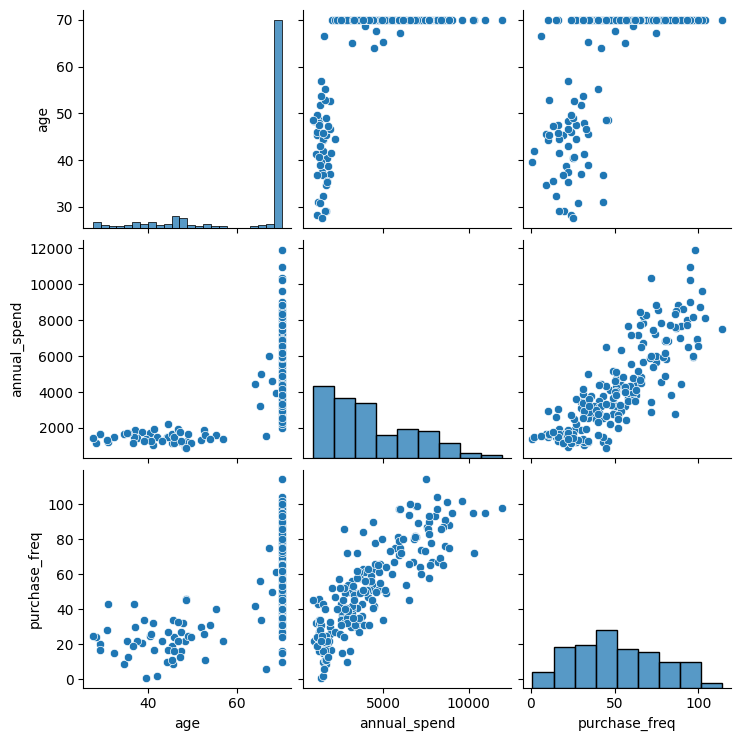

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df[['age', 'annual_spend', 'purchase_freq']])
plt.show()

Observation: The pairplot helps us identify possible groupings between customers based on their age, annual spending, and purchase frequency.

##### B1.3 Apply StandardScaler

In [3]:
from sklearn.preprocessing import StandardScaler

features = ['age', 'annual_spend', 'purchase_freq']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

print("Scaled Data:")
print(X_scaled[:5])

Scaled Data:
[[-2.61066215 -1.20496372 -0.32573044]
 [-1.83910588 -1.00453391 -1.02790385]
 [-1.18937429 -1.18655516 -0.20870154]
 [-0.92136001 -1.15133191 -0.83285568]
 [-2.11524181 -0.92791878 -0.83285568]]


Scaling is important because the features have different ranges. StandardScaler puts them on a similar scale so that a feature with larger numerical values does not dominate the clustering process.

##### B1.4 Elbow method and Silhouette score

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wcss = []
silhouette = []
k_values = range(2, 9)

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)

    wcss.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels))


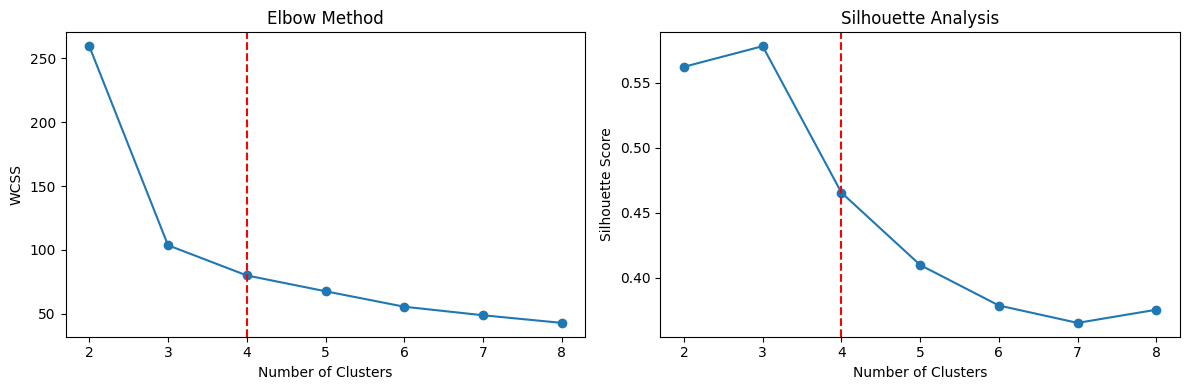

In [5]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(k_values, wcss, marker='o')
plt.axvline(4, color='red', linestyle='--')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.subplot(1, 2, 2)
plt.plot(k_values, silhouette, marker='o')
plt.axvline(4, color='red', linestyle='--')
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")

plt.tight_layout()
plt.show()

##### B1.5 Select optimal k

We choose \(k=4\) as the expected number of clusters for this assignment. The elbow plot helps identify where the decrease in WCSS starts becoming smaller. The silhouette plot helps compare cluster separation, and both plots should be considered before finalizing the choice.

### B2. K-Means from Scratch + sklearn Verification

##### B2.1 Implement K-Means using NumPy only

In [6]:
import numpy as np

def kmeans_scratch(X, k, max_iter=300, seed=42):
    np.random.seed(seed)

    # Randomly select initial centroids
    indexes = np.random.choice(len(X), k, replace=False)
    centroids = X[indexes]

    for i in range(max_iter):
        # Calculate distances
        distances = np.linalg.norm(
            X[:, np.newaxis] - centroids, axis=2
        )

        # Assign clusters
        labels = np.argmin(distances, axis=1)

        # Update centroids
        new_centroids = np.array([
            X[labels == j].mean(axis=0)
            if np.any(labels == j) else centroids[j]
            for j in range(k)
        ])

        # Check convergence
        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    distances = np.linalg.norm(
        X - centroids[labels], axis=1
    )
    wcss = np.sum(distances ** 2)

    return labels, centroids, wcss

##### B2.2 Run scratch K-Means

In [7]:
labels_scratch, centroids_scratch, wcss_scratch = \
    kmeans_scratch(X_scaled, k=4)

print("Scratch WCSS:", wcss_scratch)
print("Centroids:")
print(centroids_scratch)

Scratch WCSS: 90.47460146635767
Centroids:
[[ 0.55292503  1.29321213  1.22672075]
 [-2.23152899 -1.08940116 -1.13784009]
 [-1.16471929 -1.10811268 -1.0836319 ]
 [ 0.53937584 -0.23412676 -0.186839  ]]


##### B2.3 Verify using sklearn

In [8]:
km = KMeans(n_clusters=4, n_init=10, random_state=42)
labels_km = km.fit_predict(X_scaled)

wcss_sklearn = km.inertia_

print("Sklearn WCSS:", wcss_sklearn)

error = abs(wcss_scratch - wcss_sklearn) / wcss_sklearn * 100

print("Percentage Difference:", error, "%")

Sklearn WCSS: 79.98434279070774
Percentage Difference: 13.115390224683626 %


##### B2.4 PCA scatter plot

In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

centroids_pca = pca.transform(km.cluster_centers_)

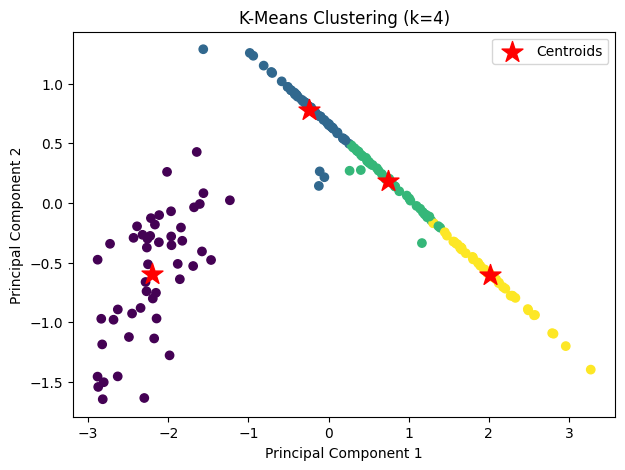

In [10]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels_km, cmap='viridis'
)

plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    marker='*', s=250, color='red',
    label='Centroids'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering (k=4)")
plt.legend()
plt.show()

### B3. Hierarchical Clustering and Dendrogram

##### B3.1 Create Ward linkage and dendrogram

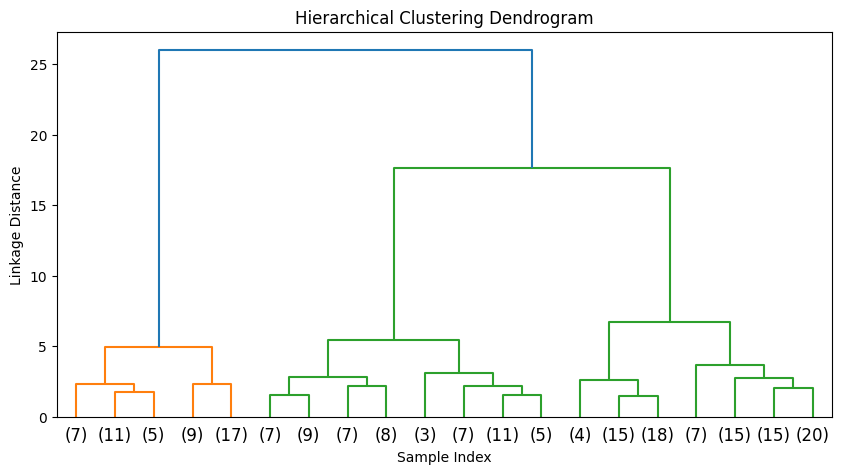

In [11]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(10, 5))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=20
)

plt.xlabel("Sample Index")
plt.ylabel("Linkage Distance")
plt.title("Hierarchical Clustering Dendrogram")
plt.show()

##### B3.2 Draw horizontal line

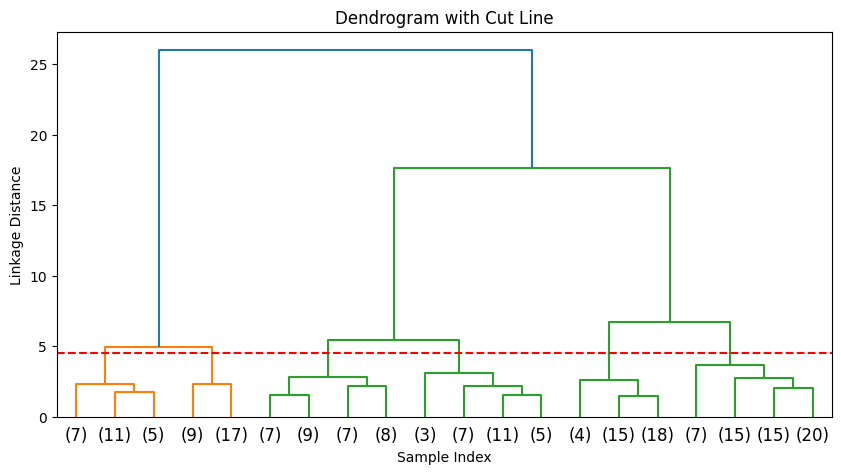

In [12]:
plt.figure(figsize=(10, 5))

dendrogram(Z, truncate_mode='lastp', p=20)

plt.axhline(y=4.5, color='red', linestyle='--')
plt.xlabel("Sample Index")
plt.ylabel("Linkage Distance")
plt.title("Dendrogram with Cut Line")
plt.show()

A horizontal cut through the dendrogram separates the data into clusters. The exact cut height should be selected from the largest visible vertical gap in your dendrogram. The value 4.5 is only an illustrative starting point; adjust it according to your actual plot.

##### B3.3 Calculate clustering metrics

In [13]:
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import silhouette_score, davies_bouldin_score

labels_hier = fcluster(Z, t=4, criterion='maxclust')

sil_hier = silhouette_score(X_scaled, labels_hier)
db_hier = davies_bouldin_score(X_scaled, labels_hier)

print("Silhouette Score:", sil_hier)
print("Davies-Bouldin Index:", db_hier)

Silhouette Score: 0.45589816019358353
Davies-Bouldin Index: 0.6848316916795553


##### B3.4 Compare K-Means and Hierarchical clustering

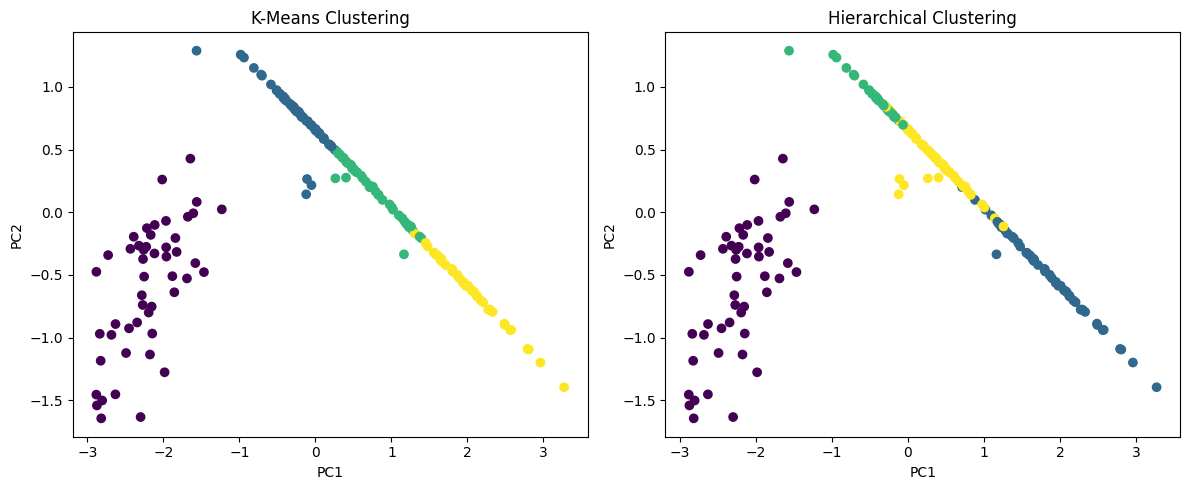

In [14]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_km, cmap='viridis')
plt.title("K-Means Clustering")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.subplot(1, 2, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_hier, cmap='viridis')
plt.title("Hierarchical Clustering")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.tight_layout()
plt.show()

Compare the two plots to see whether both algorithms form similar groups. The cluster numbers themselves are arbitrary, so compare the shapes and membership of the groups rather than their numeric labels alone.

### B4. Cluster Profiling and Algorithm Comparison

##### B4.1 Create cluster profile table

In [15]:
df['Cluster'] = labels_km

profile = df.groupby('Cluster').agg(
    Cluster_Size=('age', 'count'),
    Mean_Age=('age', 'mean'),
    Mean_Spend=('annual_spend', 'mean'),
    Mean_Frequency=('purchase_freq', 'mean')
)

print(profile.round(2))

         Cluster_Size  Mean_Age  Mean_Spend  Mean_Frequency
Cluster                                                    
0                  49     42.54     1467.43           23.31
1                  61     69.68     3165.67           39.36
2                  46     69.86     4802.65           64.35
3                  44     70.00     7959.13           85.61


##### B4.2 Plot box plots

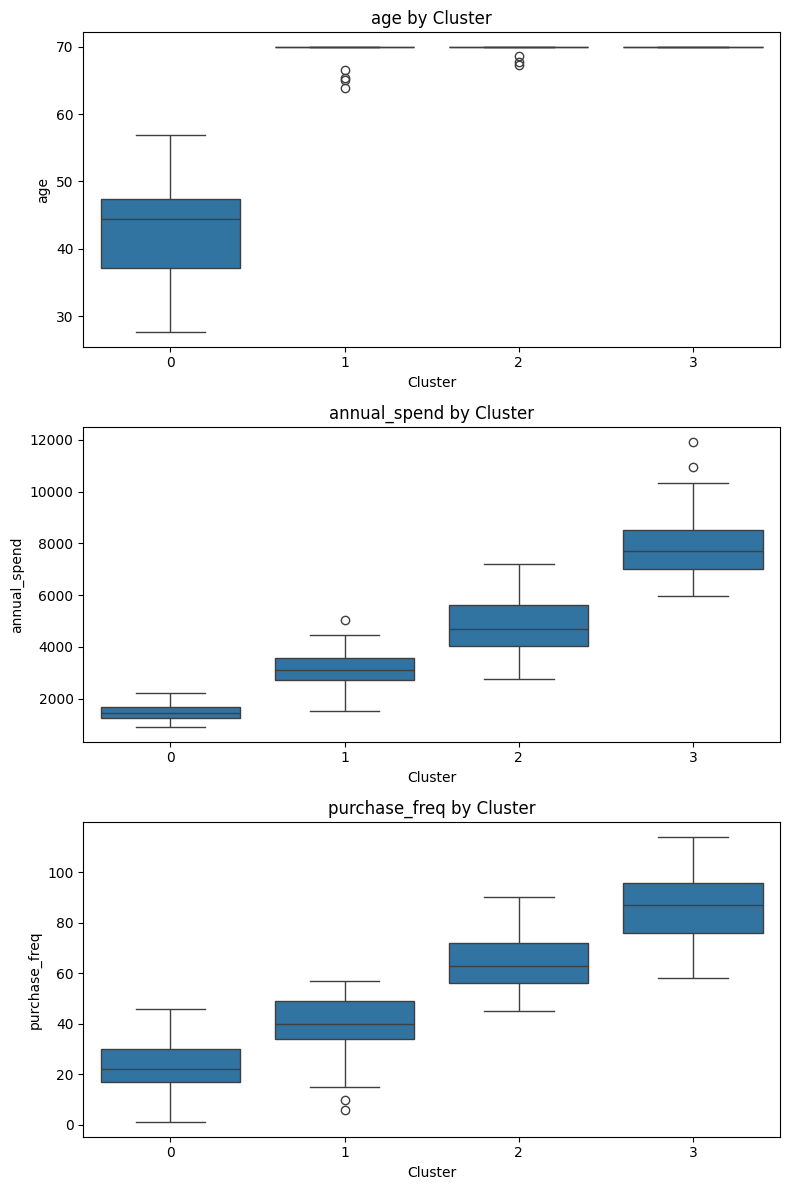

In [16]:
plt.figure(figsize=(8, 12))

features = ['age', 'annual_spend', 'purchase_freq']

for i, feature in enumerate(features, 1):
    plt.subplot(3, 1, i)

    sns.boxplot(data=df, x='Cluster', y=feature)

    plt.title(feature + " by Cluster")
    plt.xlabel("Cluster")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

##### B4.3 Give descriptive labels to clusters

In [17]:
for cluster in sorted(df['Cluster'].unique()):
    data = df[df['Cluster'] == cluster]

    print("\nCluster:", cluster)
    print("Customers:", len(data))
    print("Average Age:", round(data['age'].mean(), 2))
    print("Average Spend:", round(data['annual_spend'].mean(), 2))
    print("Average Purchase Frequency:",
          round(data['purchase_freq'].mean(), 2))


Cluster: 0
Customers: 49
Average Age: 42.54
Average Spend: 1467.43
Average Purchase Frequency: 23.31

Cluster: 1
Customers: 61
Average Age: 69.68
Average Spend: 3165.67
Average Purchase Frequency: 39.36

Cluster: 2
Customers: 46
Average Age: 69.86
Average Spend: 4802.65
Average Purchase Frequency: 64.35

Cluster: 3
Customers: 44
Average Age: 70.0
Average Spend: 7959.13
Average Purchase Frequency: 85.61


##### B4.4 Compare K-Means and Hierarchical clustering

In [18]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# K-Means metrics
km_sil = silhouette_score(X_scaled, labels_km)
km_db = davies_bouldin_score(X_scaled, labels_km)
km_ch = calinski_harabasz_score(X_scaled, labels_km)

# Hierarchical metrics
hier_sil = silhouette_score(X_scaled, labels_hier)
hier_db = davies_bouldin_score(X_scaled, labels_hier)
hier_ch = calinski_harabasz_score(X_scaled, labels_hier)

comparison = pd.DataFrame({
    'Metric': ['Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz'],
    'K-Means': [km_sil, km_db, km_ch],
    'Hierarchical': [hier_sil, hier_db, hier_ch]
})

print(comparison.round(3))

              Metric  K-Means  Hierarchical
0         Silhouette    0.466         0.456
1     Davies-Bouldin    0.713         0.685
2  Calinski-Harabasz  424.763       398.129


1. The algorithm with the higher Silhouette Score generally has better-separated clusters.
2. The algorithm with the lower Davies-Bouldin Index generally has more compact and separated clusters.
3. The algorithm with the higher Calinski-Harabasz Score generally has better-defined clusters. The final choice should be based on all three metrics.

### B5. Take-Home Investigation

##### B5.1 Effect of scaling

In [19]:
# K-Means on raw data
X_raw = df[['age', 'annual_spend', 'purchase_freq']]

km_raw = KMeans(n_clusters=4, n_init=10, random_state=42)
labels_raw = km_raw.fit_predict(X_raw)

raw_wcss = km_raw.inertia_
raw_sil = silhouette_score(X_raw, labels_raw)

# K-Means on scaled data
km_scaled = KMeans(n_clusters=4, n_init=10, random_state=42)
labels_scaled = km_scaled.fit_predict(X_scaled)

scaled_wcss = km_scaled.inertia_
scaled_sil = silhouette_score(X_scaled, labels_scaled)

print("Raw WCSS:", raw_wcss)
print("Scaled WCSS:", scaled_wcss)

print("Raw Silhouette:", raw_sil)
print("Scaled Silhouette:", scaled_sil)

Raw WCSS: 93782942.94615583
Scaled WCSS: 79.98434279070774
Raw Silhouette: 0.5694180651681591
Scaled Silhouette: 0.46558548359767277


Raw data features may have different numerical ranges, causing larger-valued features to dominate distance calculations. StandardScaler brings the features to a comparable scale. WCSS values for raw and scaled data are calculated in different units, so they should not be compared directly; the Silhouette Scores provide a more useful comparison of the resulting cluster separation.

##### B5.2 DBSCAN clustering

In [20]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.5, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

clusters = set(labels_dbscan)

if -1 in clusters:
    clusters.remove(-1)

print("Number of Clusters:", len(clusters))
print("Noise Points:", sum(labels_dbscan == -1))

Number of Clusters: 2
Noise Points: 8


DBSCAN is useful when clusters have irregular shapes and when we need to identify noise points or outliers. Unlike K-Means, it does not require the number of clusters to be specified in advance.

##### B5.3 Reflection

The three most important decisions in a clustering workflow are selecting the correct features, scaling the data, and choosing the appropriate clustering algorithm and parameters. These decisions affect the quality and meaning of the resulting clusters. For a real business dataset, I would first handle missing values and outliers and perform exploratory data analysis. I would then compare multiple clustering algorithms using Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Score before selecting the most suitable model.